# OSL errors with calibration

Let's take a look at how large the error for the exposure time becomes, when we obtain `sigma_phi` and `mu` from a calibration fit.

In [47]:
import numpy as np
import matplotlib.pyplot as plt
from fitting_engine import FittingEngine

engine = FittingEngine(verbose=True)

# slicing properties
n_points = 30
y_err_std = 0.05
x_length = 3

# material properties
order = 0.0
true_sigma_phi = 5
true_mu = 5

# actual sample parameters
true_t_exposure_1 = 1_000

# calibration sample parameters
calibration_t_exposure = [1]

As before, we need a function to create the random measurement data. This time we need to create both calibration as well as actual dating data.

In [48]:
def generate_luminescence_data(t_exposure_1, calibration_t_exposure):
    # generate random calibration data
    calibration_x_data = [np.linspace(0, x_length, n_points) \
        for _ in range(len(calibration_t_exposure))]
    calibration_y_data = [engine.models.expo(x, order,
        true_sigma_phi, true_mu, t_exposure) + np.random.normal(loc=0.0,
        scale=y_err_std, size=n_points) \
        for x, t_exposure in zip(calibration_x_data, calibration_t_exposure)]

    # generate random dating data
    x_data = np.linspace(0, x_length, n_points)
    y_data = engine.models.expo(x_data, order, true_sigma_phi, true_mu,
        t_exposure_1) + np.random.normal(loc=0.0, scale=y_err_std,
        size=n_points)

    return x_data, y_data, calibration_x_data, calibration_y_data

Now we can perform thousands of independent complete fitting runs, including calibration, to see the resulting uncertainty of the exposure time. The only source of error is the Gaussian noise on the individual data points. This gets amplified through the two fitting steps with calibration.

In [49]:
n_fits = 100_000

t_exposure_1_fits = []

for _ in range(n_fits):
    x_data, y_data, calibration_x_data, calibration_y_data = \
        generate_luminescence_data(true_t_exposure_1, calibration_t_exposure)

    # combine individual calibration samples into one large dataset
    calibration_x_data_combined = np.concatenate(calibration_x_data)
    calibration_y_data_combined = np.concatenate(calibration_y_data)
    calibration_y_err_std_combined = np.full(calibration_x_data_combined.shape,
        y_err_std)

    # each datapoint gets an individual t_exposure value for the global fit
    calibration_t_exposure_combined = np.concatenate([np.full(n_points,
        t_exposure) for t_exposure in calibration_t_exposure])

    known_params = {"order": order,
        "t_exposure_1": calibration_t_exposure_combined}

    initial_guess = {"sigma_phi": true_sigma_phi, "mu": true_mu}

    calibration_fit_result = engine.easy_fit(calibration_x_data_combined,
        calibration_y_data_combined, engine.models.expo, known_params,
        initial_guess, y_err_std=y_err_std, only_positive=True)

    # extract calibrated results
    calibrated_sigma_phi = calibration_fit_result.best_fit["sigma_phi"]
    calibrated_mu = calibration_fit_result.best_fit["mu"]

    # use calibrated result for the subsequent dating fit
    known_params = {"order": order, "sigma_phi": calibrated_sigma_phi,
        "mu": calibrated_mu}

    initial_guess = {"t_exposure_1": true_t_exposure_1}

    fit_result = engine.easy_fit(x_data, y_data, engine.models.expo,
        known_params, initial_guess, y_err_std=y_err_std,
        only_positive=True)

    t_exposure_1_fits.append(fit_result.best_fit["t_exposure_1"])

Visualize with a histogram:

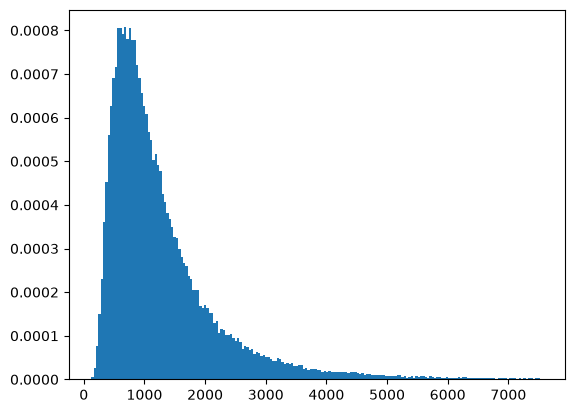

In [50]:
plt.hist(t_exposure_1_fits, bins="fd", density=True,
    range=tuple(np.quantile(t_exposure_1_fits, [0.0, 0.995])))
plt.show()

The errors are very significant. To make the result more accurate, more calibration samples, more data points, and smaller y-errors are necessary.